# 04 opening range

Validation backtest for this trading module. The tape is synthetic and seeded, so the chart checks that the production rules fire and how the book compounds after 10 bps a side. It is not a live-edge claim.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
while ROOT.name and not (ROOT / "pipeline").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pipeline.research.validation.figures import draw_module, metrics_frame
from pipeline.research.validation.modules import run_module
from pipeline.research.validation.panel import synthetic_panel

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)


In [2]:
panel = synthetic_panel()
result = run_module('opening_range', panel)
print(result.title)
for rule in result.rules:
    print("-", rule)
print()
print(result.note)
metrics_frame(result)


Module 7 — opening range breakout
- Screen a gap of at least 4% versus the prior close.
- Opening range is 09:30–09:45 New York. A long triggers on the first later 5-minute close above that high.
- Stop is entry minus the range. Target is entry plus the range.
- This notebook rebuilds a 5-minute session from the daily bar, then calls the production range function.

Synthetic tape, seeded. Paper costs of 10 bps a side. Not a live-edge claim. Intraday path is reconstructed from the daily bar.


,days,total_return_pct,cagr_pct,sharpe,max_drawdown_pct,n_trades,win_rate_pct,avg_trade_pct
0,420,25.39,14.54,7.22,-0.2,96,93.75,0.268


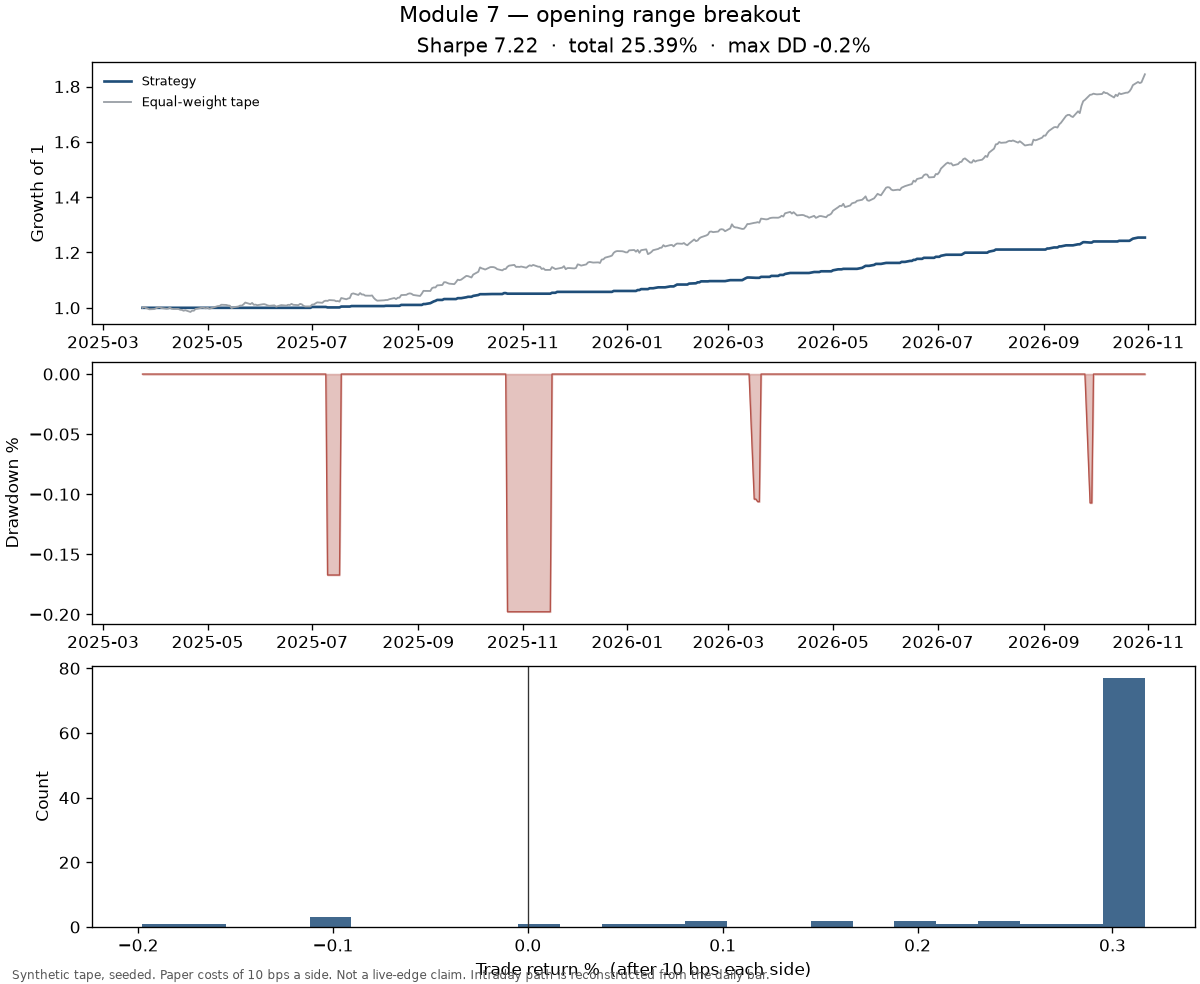

In [3]:
from IPython.display import Image, display

fig_dir = ROOT / "pipeline" / "research" / "notebooks" / "validation" / "figures"
fig_path = fig_dir / "04_opening_range.png"
fig = draw_module(result, fig_path)
plt.close(fig)
display(Image(filename=str(fig_path)))
